# IMPORT

In [48]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sys import getsizeof
import folium
import csv

# DEFINE FOLDERS

In [3]:
DATASET_INPUT_FOLDER = Path("correlated_data_csv")
DATASET_OUTPUT_FOLDER = Path("clean_data_csv")
DELETED_STATIONS_FOLDER = Path("deleted_stations")

folders = [DATASET_INPUT_FOLDER, DATASET_OUTPUT_FOLDER, DELETED_STATIONS_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE FUNCS

In [4]:
def print_df(dataframe):
    print("=========================================")
    print(f"Shape: \nrows:     {dataframe.shape[0]}\nfeatures: {dataframe.shape[1]}")
    data_size = getsizeof(dataframe)
    print(f"The size of the dataframe is {data_size} bytes({data_size/1024} MB).")
    print("-----------------------")
    display(dataframe.dtypes)
    print("-----------------------")
    display(dataframe.describe())
    print("=========================================")


def unique_rows_with_missing(
    df: pd.DataFrame,
    include_empty_strings: bool = True,
    include_text_missing: bool = True,
    text_missing=None,
) -> pd.DataFrame:
    """
    Return unique rows that contain at least one "missing" value.
    Missing can include: NaN/None, empty strings ("" / whitespace),
    and common missing tokens like "NA", "null", etc.
    """
    if text_missing is None:
        text_missing = {"na", "n/a", "null", "none", "nan", "-"}

    # Base missing: NaN/None/NaT
    mask = df.isna()

    # Optional: empty strings / whitespace-only
    if include_empty_strings:
        empty_mask = df.astype(str).apply(lambda col: col.str.strip().eq(""))
        mask = mask | empty_mask

    # Optional: text tokens like "NA", "null", ...
    if include_text_missing:
        txt_mask = df.astype(str).apply(
            lambda col: col.str.strip().str.lower().isin(text_missing)
        )
        mask = mask | txt_mask

    return df[mask.any(axis=1)].drop_duplicates()
def print_missing(dataframe):
    print("=========================================")
    display(dataframe.isna().sum().sort_values(ascending=False))
    print("-----------------------")
    missing = unique_rows_with_missing(dataframe)
    display(missing)
    print(f"Missing rows: {len(missing)}")
    print("=========================================")


# LOAD DATA

In [5]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/correlated_data_2.csv")
df.head(5)

,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111.0,2.0,0.0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2,22,25.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017.0,5.0,1.0,48.936269,2.358867,2025-11-04T03:21:03+00:00,6,16,22.0,...,OUI,93066.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104.0,1.0,1.0,48.855908,2.392571,2025-11-04T03:29:35+00:00,2,18,20.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110.0,1.0,6.0,48.843893,2.351966,2025-11-04T03:30:23+00:00,7,15,23.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108.0,2.0,2.0,48.847082,2.321375,2025-11-04T03:28:05+00:00,4,11,17.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


In [6]:
print_df(df)
#print_missing(df)

Shape: 
rows:     4907829
features: 23
The size of the dataframe is 3417827477 bytes(3337722.1455078125 MB).
-----------------------


name                            object
stationcode                    float64
ebike                          float64
mechanical                     float64
latitude                       float64
longitude                      float64
duedate                         object
numbikesavailable                int64
numdocksavailable                int64
capacity                       float64
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune             float64
weather_time                    object
weather_interval               float64
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,ebike,mechanical,latitude,longitude,numbikesavailable,numdocksavailable,capacity,code_insee_commune,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,4.885351e+06,4.885351e+06,4.885351e+06,4.867318e+06,4.867318e+06,4.907829e+06,4.907829e+06,4.867318e+06,4.867318e+06,4847298.0,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06
mean,1.908014e+04,4.671301e+00,7.759102e+00,4.885782e+01,2.341953e+00,1.243110e+01,1.843372e+01,3.181094e+01,8.110809e+04,900.0,8.966492e+00,3.719833e-01,9.687615e+00,2.008329e+02,1.452425e+01
std,1.234338e+04,4.392006e+00,9.431342e+00,3.262041e-02,5.851796e-02,1.107811e+01,1.243707e+01,1.265835e+01,8.460224e+03,0.0,4.014208e+00,4.833340e-01,4.251071e+00,6.335129e+01,2.457985e+01
min,1.001000e+03,0.000000e+00,0.000000e+00,4.874339e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.505600e+04,900.0,-3.900000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
25%,1.103800e+04,2.000000e+00,1.000000e+00,4.883682e+01,2.302599e+00,4.000000e+00,9.000000e+00,2.300000e+01,7.505600e+04,900.0,6.600000e+00,0.000000e+00,6.600000e+00,1.640000e+02,3.000000e+00
50%,1.701100e+04,3.000000e+00,4.000000e+00,4.885826e+01,2.344037e+00,9.000000e+00,1.700000e+01,3.000000e+01,7.505600e+04,900.0,9.000000e+00,0.000000e+00,9.400000e+00,1.890000e+02,3.000000e+00
75%,2.240100e+04,6.000000e+00,1.200000e+01,4.887951e+01,2.380039e+00,1.800000e+01,2.600000e+01,3.800000e+01,9.204400e+04,900.0,1.160000e+01,1.000000e+00,1.240000e+01,2.280000e+02,3.000000e+00
max,9.200800e+04,5.600000e+01,7.600000e+01,4.895757e+01,2.538242e+00,8.400000e+01,1.000000e+02,1.050000e+02,9.501800e+04,900.0,1.950000e+01,1.000000e+00,2.850000e+01,3.600000e+02,9.500000e+01


# RENAME FEATURES(COLUMNS)

In [7]:
"""
name,stationcode,ebike,mechanical,latitude,longitude,duedate,
numbikesavailable,numdocksavailable,capacity,is_renting,is_installed,nom_arrondissement_communes,is_returning,code_insee_commune,
weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
"""

old_feature_names = ["name",
                     "stationcode" ,
                     "numbikesavailable", 
                     "numdocksavailable",
                     "nom_arrondissement_communes",  
                     "code_insee_commune", 
                     "weather_time",
                     "weather_temperature_2m", 
                     "weather_is_day",
                     "weather_wind_speed_10m",
                     "weather_wind_direction_10m",
                     "weather_weather_code"]
new_feature_names = ["station_name", 
                     "station_code",
                     "total_bikes_now", 
                     "total_bikes_taken",
                     "commune_name", 
                     "postal_code", 
                     "timestamp",
                     "temperature", 
                     "is_day",
                     "wind_speed",
                     "wind_direction",
                     "weather_code"]

feature_name_dict = dict(zip(old_feature_names, new_feature_names))
df = df.rename(columns=feature_name_dict)

# CHECK

In [8]:
print(df.isna().sum().sort_values(ascending=False))

weather_interval     60531
weather_code         60531
wind_direction       60531
wind_speed           60531
is_day               60531
temperature          60531
timestamp            60531
station_name         40511
latitude             40511
longitude            40511
capacity             40511
commune_name         40511
postal_code          40511
ebike                22478
mechanical           22478
station_code         22478
is_installed             0
is_returning             0
is_renting               0
total_bikes_taken        0
total_bikes_now          0
duedate                  0
source_file              0
dtype: int64


# DROP INVALID ROWS(DOESNT CONTAIN THE DATA FOR TOTAL_BIKES_NOW)

In [9]:
df = df.dropna(subset=["station_name", "station_code", "postal_code", "capacity", "total_bikes_now", "total_bikes_taken", "timestamp"])

# RECHECK

In [10]:
#print_missing(df)

station_name         0
commune_name         0
weather_code         0
wind_direction       0
wind_speed           0
is_day               0
temperature          0
weather_interval     0
timestamp            0
postal_code          0
is_returning         0
is_installed         0
station_code         0
is_renting           0
capacity             0
total_bikes_taken    0
total_bikes_now      0
duedate              0
longitude            0
latitude             0
mechanical           0
ebike                0
source_file          0
dtype: int64

-----------------------


KeyboardInterrupt: 

# KEEPING THE USABLE COLUMNS

In [11]:
# Keep only useful columns
keep_cols = [
    "station_code",
    "latitude",
    "longitude",
    "capacity",
    "total_bikes_now",
    "total_bikes_taken",
    "timestamp",
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

df_cleaned = df[keep_cols].copy(deep=True)

print("Initial shape:", df_cleaned.shape)
print_df(df_cleaned)

Initial shape: (4847298, 12)
Shape: 
rows:     4847298
features: 12
The size of the dataframe is 819193394 bytes(799993.548828125 MB).
-----------------------


station_code         float64
latitude             float64
longitude            float64
capacity             float64
total_bikes_now        int64
total_bikes_taken      int64
timestamp             object
temperature          float64
wind_speed           float64
wind_direction       float64
weather_code         float64
is_day               float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day
count,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06
mean,1.903463e+04,4.885803e+01,2.341822e+00,3.184861e+01,1.245638e+01,1.844446e+01,8.966492e+00,9.687615e+00,2.008329e+02,1.452425e+01,3.719833e-01
std,1.231036e+04,3.228223e-02,5.849804e-02,1.263088e+01,1.107430e+01,1.243517e+01,4.014208e+00,4.251071e+00,6.335129e+01,2.457985e+01,4.833340e-01
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,1.103800e+04,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,6.600000e+00,6.600000e+00,1.640000e+02,3.000000e+00,0.000000e+00
50%,1.701000e+04,4.885830e+01,2.343996e+00,3.000000e+01,9.000000e+00,1.700000e+01,9.000000e+00,9.400000e+00,1.890000e+02,3.000000e+00,0.000000e+00
75%,2.230500e+04,4.887951e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.600000e+01,1.160000e+01,1.240000e+01,2.280000e+02,3.000000e+00,1.000000e+00
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00


# WEATHER TIME HANDLING

In [12]:
df_cleaned["timestamp"] = pd.to_datetime(df_cleaned["timestamp"], errors="coerce")

# Drop rows without time
df_cleaned = df_cleaned.dropna(subset=["timestamp"])

# Time features
df_cleaned["hour"] = df_cleaned["timestamp"].dt.hour
df_cleaned["dayofweek"] = df_cleaned["timestamp"].dt.dayofweek
df_cleaned["is_weekend"] = (df_cleaned["dayofweek"] >= 5).astype(int)

# Cyclical encoding
df_cleaned["sin_hour"] = np.sin(2 * np.pi * df_cleaned["hour"] / 24)
df_cleaned["cos_hour"] = np.cos(2 * np.pi * df_cleaned["hour"] / 24)

In [13]:
print_df(df_cleaned)

Shape: 
rows:     4847298
features: 17
The size of the dataframe is 659232560 bytes(643781.796875 MB).
-----------------------


station_code                float64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now               int64
total_bikes_taken             int64
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int32
dayofweek                     int32
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
count,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4847298,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06
mean,1.903463e+04,4.885803e+01,2.341822e+00,3.184861e+01,1.245638e+01,1.844446e+01,2025-11-23 21:51:12.327179776,8.966492e+00,9.687615e+00,2.008329e+02,1.452425e+01,3.719833e-01,1.148585e+01,3.009617e+00,2.752562e-01,4.885896e-03,-2.929817e-03
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-13 22:30:00,6.600000e+00,6.600000e+00,1.640000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885830e+01,2.343996e+00,3.000000e+01,9.000000e+00,1.700000e+01,2025-11-23 20:00:00,9.000000e+00,9.400000e+00,1.890000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.230500e+04,4.887951e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-03 19:45:00,1.160000e+01,1.240000e+01,2.280000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,2025-12-13 22:45:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231036e+04,3.228223e-02,5.849804e-02,1.263088e+01,1.107430e+01,1.243517e+01,NaN,4.014208e+00,4.251071e+00,6.335129e+01,2.457985e+01,4.833340e-01,6.904222e+00,1.937029e+00,4.466433e-01,7.075472e-01,7.066433e-01


# CHANGE FEATURE DATA TYPES FOR MEMORY OPTIMISATION

In [14]:
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "uint8",
    "total_bikes_now": "uint8",
    "total_bikes_taken": "uint8",
    "temperature": "float16",
    "wind_speed": "float16",
    "wind_direction": "float16",
    "weather_code": "uint8",
    "is_day": "uint8",
    "hour": "uint8",
    "dayofweek": "uint8",
    "is_weekend": "uint8",
    "sin_hour": "float32",
    "cos_hour": "float32"
})

print_df(df_cleaned)
df_cleaned.head()

Shape: 
rows:     4847298
features: 17
The size of the dataframe is 281143316 bytes(274554.01953125 MB).
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now               uint8
total_bikes_taken             uint8
timestamp            datetime64[ns]
temperature                 float16
wind_speed                  float16
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
dayofweek                     uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dt

,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
count,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4847298,4.847298e+06,4.847298e+06,4847298.0,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06
mean,1.903463e+04,4.885803e+01,2.341822e+00,3.184861e+01,1.245638e+01,1.844446e+01,2025-11-23 21:51:12.327179776,NaN,NaN,NaN,1.452425e+01,3.719833e-01,1.148585e+01,3.009617e+00,2.752562e-01,4.885892e-03,-2.929816e-03
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-13 22:30:00,6.601562e+00,6.601562e+00,164.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885830e+01,2.343996e+00,3.000000e+01,9.000000e+00,1.700000e+01,2025-11-23 20:00:00,9.000000e+00,9.398438e+00,189.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.230500e+04,4.887951e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-03 19:45:00,1.160156e+01,1.239844e+01,228.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,2025-12-13 22:45:00,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231036e+04,3.228223e-02,5.849804e-02,1.263088e+01,1.107430e+01,1.243517e+01,NaN,0.000000e+00,0.000000e+00,0.0,2.457985e+01,4.833340e-01,6.904222e+00,1.937029e+00,4.466433e-01,7.106771e-01,7.094365e-01


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\io\formats\format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
0,14111,48.837526,2.336035,25,2,22,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
1,32017,48.936269,2.358867,22,6,16,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
2,11104,48.855908,2.392571,20,2,18,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
3,5110,48.843893,2.351966,23,7,15,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
4,6108,48.847082,2.321375,17,4,11,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5


# HISTOGRAM OF ROWS

In [15]:
df_counts = df_cleaned["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)

      station_code  count
0            14005   3245
1            14009   3245
2            41212   3245
3            13204   3245
4            14111   3244
...            ...    ...
1497         32308   2108
1498         22508   2106
1499         40018   1886
1500         22209   1675
1501          8204   1345

[1502 rows x 2 columns]


[3245 3245 3245 ... 1886 1675 1345]
counts(40): [3245, 3244, 3243, 3242, 3241, 3240, 3239, 3238, 3237, 3236, 3235, 3234, 3233, 3231, 3226, 3216, 3214, 3213, 3209, 3198, 3184, 2959, 2866, 2865, 2852, 2830, 2804, 2651, 2434, 2360, 2174, 2169, 2135, 2115, 2109, 2108, 2106, 1886, 1675, 1345]
bins(40): [4, 40, 58, 114, 135, 219, 311, 158, 107, 130, 124, 67, 7, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
count
1345      1
1675      1
1886      1
2106      1
2108      1
2109      1
2115      1
2135      1
2169      1
2174      1
2360      1
2434      1
2651      1
2804      1
2830      1
2852      1
2865      1
2866      1
2959      1
3184      1
3198      1
3209      1
3213      1
3214      1
3216      1
3226      2
3231      1
3233      7
3234     67
3235    124
3236    130
3237    107
3238    158
3239    311
3240    219
3241    135
3242    114
3243     58
3244     40
3245      4
Name: count, dtype: int64


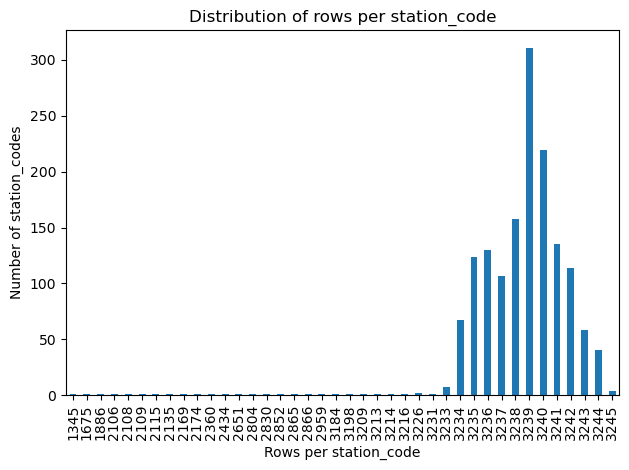

In [16]:

rows = df_cleaned["station_code"].value_counts().values
print(rows)
drows = {v.item(): sum([1 for e in rows if e == v]) for v in rows}
bins, counts = list(drows.values()), list(drows.keys())
print(f"counts({len(counts)}): {counts}")
print(f"bins({len(bins)}): {bins}")


counts = df["station_code"].value_counts()   # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(count_distribution)
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_codes")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()

# MAKE THE MAP BEFORE DELETING STATIONS

In [64]:
def save_unique_stations_map_html_minimal(
    df,
    out_html="idf_stations_minimal_2.html",
    station_col="station_code",
    lat_col="latitude",
    lon_col="longitude",
    radius=0.01,               
    color="red",
    fill_opacity=0.8,
    zoom_start=10,
    tiles="CartoDB positronNoLabels",  # minimal; try "CartoDB positron" too
):
    # Keep only needed cols, drop missing coords
    d = df[[station_col, lat_col, lon_col]].dropna(subset=[lat_col, lon_col])

    # Keep one row per station (huge speedup vs millions of rows)
    d = d.drop_duplicates(subset=[station_col], keep="first")

    # Ensure numeric
    d[lat_col] = d[lat_col].astype(float)
    d[lon_col] = d[lon_col].astype(float)

    # Center map
    center_lat = float(d[lat_col].mean())
    center_lon = float(d[lon_col].mean())

    # Minimal basemap
    m = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles=tiles)

    # Plot points
    for code, la, lo in zip(d[station_col], d[lat_col], d[lon_col]):
        folium.CircleMarker(
            location=[la, lo],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            tooltip=str(code),
        ).add_to(m)

    m.save(out_html)
    return out_html, len(d)


In [65]:
html_path, n = save_unique_stations_map_html_minimal(df_cleaned, radius=0.01)
print("Saved:", html_path, "| stations mapped:", n)

Saved: idf_stations_minimal_2.html | stations mapped: 1502


# FILL MISSING WEATHER VALUES

In [ ]:
"""

weather_cols = [
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

for col in weather_cols:
    df[col] = df.groupby("station_code")[col].transform(
        lambda x: x.fillna(x.mean())
    )
"""

# DROP BROKEN WEATHER ROWS

In [ ]:
# df = df.dropna(subset=weather_cols)

# DETECT/REMOVE BROKEN STATIONS

In [43]:
MIN_ROWS = 3234
the_counts = df_cleaned["station_code"].value_counts()
#print(the_counts)
#print(type(the_counts))

the_counts = the_counts.to_dict()
#print(the_counts)
#print(type(the_counts))

less_than = [station for (station, row) in the_counts.items() if row < MIN_ROWS]
print(less_than)
print(f"Number of stations to delete: {len(less_than)}")

to_have = list(the_counts.keys() - less_than)

print(to_have)
print(len(to_have))

[18141, 18020, 9005, 18005, 18209, 18012, 18107, 18014, 22304, 15058, 4010, 33019, 1003, 21302, 12010, 15204, 13206, 18043, 9104, 8002, 12127, 19018, 5202, 12507, 7203, 8004, 12105, 15056, 8203, 47009, 32308, 22508, 40018, 22209, 8204]
Number of stations to delete: 35
[13026, 4101, 4103, 4104, 8201, 8202, 4107, 13028, 4109, 4110, 4108, 9118, 17102, 17104, 17105, 17106, 17107, 17108, 17111, 17116, 17117, 4201, 17119, 17121, 17122, 17124, 41101, 41102, 41103, 17125, 21209, 33001, 33003, 33005, 33006, 33009, 41202, 41203, 41204, 41205, 41206, 41207, 41208, 41209, 41210, 41211, 41212, 21216, 33017, 33020, 33016, 33018, 9006, 9007, 9008, 9010, 9013, 9014, 9015, 9016, 9017, 9020, 20202, 9021, 33102, 33103, 41301, 41302, 41303, 41304, 9023, 9024, 20203, 8549, 9027, 9032, 41601, 25001, 25002, 25003, 25004, 25005, 25006, 25007, 25008, 25009, 25010, 41606, 41401, 41402, 41403, 41404, 41405, 18004, 13121, 13125, 13128, 21001, 21002, 21003, 21004, 21005, 21006, 17201, 21007, 21009, 21010, 21011, 2

In [45]:
print_df(df_cleaned)

df_removed = df_cleaned[df_cleaned.station_code.isin(to_have)]

print_df(df_removed)

Shape: 
rows:     4847298
features: 17
The size of the dataframe is 281143316 bytes(274554.01953125 MB).
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now               uint8
total_bikes_taken             uint8
timestamp            datetime64[ns]
temperature                 float16
wind_speed                  float16
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
dayofweek                     uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dt

,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
count,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4847298,4.847298e+06,4.847298e+06,4847298.0,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06,4.847298e+06
mean,1.903463e+04,4.885803e+01,2.341822e+00,3.184861e+01,1.245638e+01,1.844446e+01,2025-11-23 21:51:12.327179776,NaN,NaN,NaN,1.452425e+01,3.719833e-01,1.148585e+01,3.009617e+00,2.752562e-01,4.885892e-03,-2.929816e-03
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-13 22:30:00,6.601562e+00,6.601562e+00,164.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885830e+01,2.343996e+00,3.000000e+01,9.000000e+00,1.700000e+01,2025-11-23 20:00:00,9.000000e+00,9.398438e+00,189.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.230500e+04,4.887951e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-03 19:45:00,1.160156e+01,1.239844e+01,228.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,2025-12-13 22:45:00,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231036e+04,3.228223e-02,5.849804e-02,1.263088e+01,1.107430e+01,1.243517e+01,NaN,0.000000e+00,0.000000e+00,0.0,2.457985e+01,4.833340e-01,6.904222e+00,1.937029e+00,4.466433e-01,7.106771e-01,7.094365e-01


Shape: 
rows:     4751307
features: 17
The size of the dataframe is 275575838 bytes(269117.029296875 MB).
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now               uint8
total_bikes_taken             uint8
timestamp            datetime64[ns]
temperature                 float16
wind_speed                  float16
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
dayofweek                     uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dt

,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
count,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4751307,4.751307e+06,4.751307e+06,4751307.0,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06
mean,1.909168e+04,4.885789e+01,2.341727e+00,3.188520e+01,1.245045e+01,1.846341e+01,2025-11-23 21:46:13.053645568,NaN,NaN,NaN,1.452065e+01,3.719894e-01,1.148586e+01,3.009542e+00,2.752314e-01,4.881445e-03,-2.938962e-03
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883682e+01,2.302426e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-13 22:30:00,6.601562e+00,6.601562e+00,164.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885810e+01,2.343959e+00,3.000000e+01,9.000000e+00,1.700000e+01,2025-11-23 19:45:00,9.000000e+00,9.398438e+00,189.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.240300e+04,4.887935e+01,2.380039e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-03 19:45:00,1.160156e+01,1.239844e+01,228.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.900000e+01,7.800000e+01,2025-12-13 22:45:00,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.236126e+04,3.226301e-02,5.866152e-02,1.244929e+01,1.102559e+01,1.228425e+01,NaN,0.000000e+00,0.000000e+00,0.0,2.457701e+01,4.833356e-01,6.904169e+00,1.936983e+00,4.466309e-01,7.107524e-01,7.096321e-01


In [ ]:
#print(sum([4, 40, 58, 114, 135, 219, 311, 158, 107, 130, 124, 67, 7, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

35


# MAKE THE MAP AFTER DELETING 

In [66]:
html_path, n = save_unique_stations_map_html_minimal(df_removed, radius=0.01, out_html="idf_stations_removed.html")
print("Saved:", html_path, "| stations mapped:", n)

Saved: idf_stations_removed.html | stations mapped: 1467


# SAVE THE BROKEN STATIONS IN A FILE

In [56]:
with open(f"{DELETED_STATIONS_FOLDER}/broken_stations.txt", 'wb') as myfile:
    #wr = csv.writer(myfile, quoting=csv.QUOTE_ALL)
    less_thans = [str(x) for x in less_than]
    myfile.writelines(less_thans)

#less_than.to_csv(f"{DELETED_STATIONS_FOLDER}/broken_stations.csv")
print(f"Broken stations saved: {len(less_than)}")


TypeError: a bytes-like object is required, not 'str'

# REMOVE THEM FROM THE DATABASE

In [ ]:
"""
df = df[df["station_code"].isin(valid_stations)]

print("After station filtering:", df.shape)
print("Remaining stations:", df['station_code'].nunique())
"""

After station filtering: (4763007, 16)
Remaining stations: 1474


# CHECK

In [57]:
print(df_removed.isna().sum().sort_values(ascending=False))

station_code         0
wind_direction       0
sin_hour             0
is_weekend           0
dayofweek            0
hour                 0
is_day               0
weather_code         0
wind_speed           0
latitude             0
temperature          0
timestamp            0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
cos_hour             0
dtype: int64


# DETAILS

In [58]:
df_removed.describe()

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dt

,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,dayofweek,is_weekend,sin_hour,cos_hour
count,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4751307,4.751307e+06,4.751307e+06,4751307.0,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06,4.751307e+06
mean,1.909168e+04,4.885789e+01,2.341727e+00,3.188520e+01,1.245045e+01,1.846341e+01,2025-11-23 21:46:13.053645568,NaN,NaN,NaN,1.452065e+01,3.719894e-01,1.148586e+01,3.009542e+00,2.752314e-01,4.881445e-03,-2.938962e-03
min,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883682e+01,2.302426e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-13 22:30:00,6.601562e+00,6.601562e+00,164.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885810e+01,2.343959e+00,3.000000e+01,9.000000e+00,1.700000e+01,2025-11-23 19:45:00,9.000000e+00,9.398438e+00,189.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2.240300e+04,4.887935e+01,2.380039e+00,3.800000e+01,1.800000e+01,2.600000e+01,2025-12-03 19:45:00,1.160156e+01,1.239844e+01,228.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.900000e+01,7.800000e+01,2025-12-13 22:45:00,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.236126e+04,3.226301e-02,5.866152e-02,1.244929e+01,1.102559e+01,1.228425e+01,NaN,0.000000e+00,0.000000e+00,0.0,2.457701e+01,4.833356e-01,6.904169e+00,1.936983e+00,4.466309e-01,7.107524e-01,7.096321e-01


# SAVE THE FINAL CLEAN DATASET

In [59]:
df_cleaned.to_csv(f"{DATASET_OUTPUT_FOLDER}/clean_bike_weather_data_optimized_removed.csv", index=False)
print("Clean dataset saved: clean_bike_weather_data_optimized_removed.csv")

Clean dataset saved: clean_bike_weather_data_optimized_removed.csv
